This notebook loads alll the used datasets with their drift labels. It then plots one example stream from each dataset family, marking drift locations, and saves the figure as `plot_stream_examples.ipynb`

# Imports

In [17]:
from pathlib import Path as _Path
import os as _os

for _candidate in (_Path.cwd(), *_Path.cwd().parents):
    if (_candidate / "KALEIDO_multi_instance.py").is_file() and (_candidate / "stable_windows.csv").is_file():
        _code_dir = _candidate
        break
    _nested = _candidate / "results_all_in_one_code"
    if (_nested / "KALEIDO_multi_instance.py").is_file() and (_nested / "stable_windows.csv").is_file():
        _code_dir = _nested
        break
else:
    raise FileNotFoundError("Could not locate results_all_in_one_code; start this notebook inside the repository")

_os.chdir(_code_dir)
(_code_dir / "figures").mkdir(exist_ok=True)
(_code_dir / "example_runs").mkdir(exist_ok=True)
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D

# Setting colors per timeseries

In [18]:
sns.set_style("whitegrid")

# Functions

In [19]:
def load_variable_column_csv(file_path, delimiter=','):
    # The max column count a line in the file could have
    largest_column_count = 0

    # Loop the data lines
    with open(file_path, 'r') as temp_f:
        # Read the lines
        lines = temp_f.readlines()

        for l in lines:
            # Count the column count for the current line
            column_count = len(l.split(delimiter)) + 1
            
            # Set the new most column count
            largest_column_count = column_count if largest_column_count < column_count else largest_column_count

    # Generate column names (will be 0, 1, 2, ..., largest_column_count - 1)
    column_names = [i for i in range(0, largest_column_count)]

    # Read csv
    return pd.read_csv(file_path, header=None, delimiter=delimiter, names=column_names)

# Time series load

In [20]:
x_AR4_linear_1 = load_variable_column_csv('datasets/synthetic_linear_nonlinear_datasets/time_series_linear_abrupt_100.csv')
data_streams_AR4_linear_1 = x_AR4_linear_1.values
labels_AR4_linear_1 = load_variable_column_csv('datasets/synthetic_linear_nonlinear_datasets/drift_labels_linear_abrupt_100.csv').values

uncertainties = np.load('../uncertainty_our_results/uncertainties_TS.npy')
data_streams_rolling_mean = [uncertainties, pd.Series(uncertainties).rolling(window = 10).mean().values,
                pd.Series(uncertainties).rolling(window = 20).mean().values,
                pd.Series(uncertainties).rolling(window = 30).mean().values,
                pd.Series(uncertainties).rolling(window = 40).mean().values,
                pd.Series(uncertainties).rolling(window = 50).mean().values,
                pd.Series(uncertainties).rolling(window = 60).mean().values,
                pd.Series(uncertainties).rolling(window = 70).mean().values,
                pd.Series(uncertainties).rolling(window = 80).mean().values,
                pd.Series(uncertainties).rolling(window = 90).mean().values,
                pd.Series(uncertainties).rolling(window = 100).mean().values
                ]
x_rolling_mean = data_streams_rolling_mean
labels_rolling_mean = pd.DataFrame([[2000, 4500, 13000]] * len(data_streams_rolling_mean)).values

data_friedman = pd.read_csv('../uncertainty-drift-detection/01_Artificial_DataSets/friedman_with_2_abrupt_drift.csv')
data_streams_friedman = [data_friedman['y_1']]
x_friedman = data_streams_friedman
labels_friedman = pd.DataFrame([[2000, 3000, 5000, 7500, 16000]] * len(data_streams_friedman)).values

data_friedman_5_drifts = pd.read_csv('../uncertainty-drift-detection/01_Artificial_DataSets/friedman_with_2_abrupt_drift.csv')
data_streams_friedman_5_drifts = [data_friedman_5_drifts['x1'], data_friedman_5_drifts['x3'], data_friedman_5_drifts['x5'], 
                                  data_friedman_5_drifts['y_1'], data_friedman_5_drifts['y_org']]
x_friedman_5_drifts = data_streams_friedman_5_drifts
labels_friedman_5_drifts = pd.DataFrame([[2000, 3000, 5000, 7500, 16000]] * len(data_streams_friedman_5_drifts)).values

data_friedman_2_drifts = pd.read_csv('../uncertainty-drift-detection/01_Artificial_DataSets/friedman_with_2_abrupt_drift.csv')
data_streams_friedman_2_drifts = [data_friedman_2_drifts['x7'], data_friedman_2_drifts['x9'], data_friedman_2_drifts['x10']]
x_friedman_2_drifts = data_streams_friedman_2_drifts
labels_friedman_2_drifts = pd.DataFrame([[10000, 12000]] * len(data_streams_friedman_2_drifts)).values

data_friedman_no_drifts = pd.read_csv('../uncertainty-drift-detection/01_Artificial_DataSets/friedman_with_2_abrupt_drift.csv')
data_streams_friedman_no_drifts = [data_friedman_no_drifts['x2'], data_friedman_no_drifts['x4'], 
                                   data_friedman_no_drifts['x6'], data_friedman_no_drifts['x8']]
x_friedman_no_drifts = data_streams_friedman_no_drifts
labels_friedman_no_drifts = pd.DataFrame([[10000]] * len(data_streams_friedman_no_drifts)).values # the label here is only for stat

x_random_noisy = load_variable_column_csv('datasets/synthetic_random_datasets/time_series_random_noisy_100.csv')
data_streams_random_noisy = x_random_noisy.values
labels_random_noisy = load_variable_column_csv('datasets/synthetic_random_datasets/drift_labels_random_noisy_100.csv').values

x_random_easy = load_variable_column_csv('datasets/synthetic_random_datasets/time_series_random_simple_100.csv')
data_streams_random_easy = x_random_easy.values
labels_random_easy = load_variable_column_csv('datasets/synthetic_random_datasets/drift_labels_random_simple_100.csv').values
               
x_AR4_nonlinear_1 = load_variable_column_csv('datasets/synthetic_linear_nonlinear_datasets/time_series_nonlinear_abrupt_100.csv')
data_streams_AR4_nonlinear_1 = x_AR4_nonlinear_1.values
labels_AR4_nonlinear_1 = load_variable_column_csv('datasets/synthetic_linear_nonlinear_datasets/drift_labels_nonlinear_abrupt_100.csv').values


x_infocom_5G_add_hour = load_variable_column_csv('datasets/INFOCOM/ran_updates_event_5G addition_hour_granularity.csv')
data_streams_infocom_5G_add_hour = x_infocom_5G_add_hour.values
labels_infocom_5G_add_hour = load_variable_column_csv('datasets/INFOCOM/drift_labels_ran_updates_event_5G addition_hour_granularity.csv').values

x_infocom_4G_add_hour = load_variable_column_csv('datasets/INFOCOM/ran_updates_event_4G addition_hour_granularity.csv')
data_streams_infocom_4G_add_hour = x_infocom_4G_add_hour.values
labels_infocom_4G_add_hour = load_variable_column_csv('datasets/INFOCOM/drift_labels_ran_updates_event_4G addition_hour_granularity.csv').values

x_infocom_5G_add_hour_trend = load_variable_column_csv('datasets/INFOCOM/ran_updates_event_5G addition_hour_granularity_trend.csv')
data_streams_infocom_5G_add_hour_trend = x_infocom_5G_add_hour_trend.values
labels_infocom_5G_add_hour_trend = load_variable_column_csv('datasets/INFOCOM/drift_labels_ran_updates_event_5G addition_hour_granularity.csv').values

x_infocom_4G_add_hour_trend = load_variable_column_csv('datasets/INFOCOM/ran_updates_event_4G addition_hour_granularity_trend.csv')
data_streams_infocom_4G_add_hour_trend = x_infocom_4G_add_hour_trend.values
labels_infocom_4G_add_hour_trend = load_variable_column_csv('datasets/INFOCOM/drift_labels_ran_updates_event_4G addition_hour_granularity.csv').values


## PLOTS

In [21]:
def _as_1d(stream):
    """one stream -> 1-D float array without the NaN padding at the end"""
    x = np.asarray(stream, dtype=float).ravel()
    valid = np.where(np.isfinite(x))[0]
    return x[: valid[-1] + 1] if len(valid) else x


def _label_positions(labels, idx):
    """drift positions of stream `idx` from a (n_streams, n_labels) matrix with NaN padding"""
    if labels is None:
        return []
    lab = np.asarray(labels, dtype=float)
    row = lab[idx] if lab.ndim == 2 else lab
    return [int(v) for v in row if np.isfinite(v)]


def plot_stream_examples(data_streams, stream_labels, order=None, stream_idx=0,
                         ts_titles=None, colors=None, no_label_ts=("friedman_no_drifts",),
                         ncols=3, row_height=1.6, col_width=4.2, save="figures/stream_examples.pdf",
                         fontsize=11, tick_fontsize=None, font_scale=1.0, text_color="black",
                         line_color="steelblue", drift_color="#444444", lw=0.9, line_alpha=0.6,
                         shade_before=None, shade_color="#dce8f5", shade_label=None,
                         border_color="#444444", border_width=1.0,
                         bold_family="DejaVu Sans"):
    """
    One example stream per time-series type, drift positions as dashed vertical lines.

    data_streams  : {name: 2-D array (n_streams, length) | list of 1-D arrays}
    stream_labels : {name: 2-D array (n_streams, n_labels) with NaN padding | list}
    order         : names in panel order (default: dict order)
    stream_idx    : which stream of each type to show (int, or {name: int})
    colors        : {name: colour} for the line; default `line_color` for all
    no_label_ts   : types whose labels are not real drifts (not drawn)
    shade_before  : {name: n_samples} -> shade the n samples before every drift of that type
                    (e.g. {"infocom_4G_add_hour": 168, ...} for the week before the event)
    Styled like the results figure: DejaVu Sans text, bordered panels,
    font_scale multiplies every text size.
    """
    sns.set_theme(style="whitegrid")                 # resets font.family -> set fonts AFTER this
    tick_fontsize = tick_fontsize or fontsize - 3
    fontsize, tick_fontsize = fontsize * font_scale, tick_fontsize * font_scale
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
        "mathtext.fontset": "dejavusans", "axes.formatter.use_mathtext": False,
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "font.size": fontsize, "axes.titlesize": fontsize, "axes.labelsize": fontsize,
        "xtick.labelsize": tick_fontsize, "ytick.labelsize": tick_fontsize,
        "text.color": text_color, "axes.labelcolor": text_color,
        "xtick.color": text_color, "ytick.color": text_color, "axes.titlecolor": text_color,
    })
    ts_titles = ts_titles or {}
    colors = colors or {}
    shade_before = shade_before or {}
    order = list(order or data_streams)
    nrows = int(np.ceil(len(order) / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(col_width * ncols, row_height * nrows), squeeze=False)
    axes = axes.ravel()

    for ax, name in zip(axes, order):
        idx = stream_idx.get(name, 0) if isinstance(stream_idx, dict) else stream_idx
        streams = data_streams[name]
        x = _as_1d(streams[idx])
        drifts = [] if name in no_label_ts else _label_positions(stream_labels.get(name), idx)

        ax.plot(np.arange(len(x)), x, color=colors.get(name, line_color), lw=lw, alpha=line_alpha, zorder=2)
        for d in drifts:
            if 0 <= d < len(x):
                if name in shade_before:
                    ax.axvspan(max(d - shade_before[name], 0), d, color=shade_color, alpha=0.6, lw=0, zorder=1)
                ax.axvline(d, color=drift_color, ls="--", lw=1.1, zorder=3)

        ax.set_title(ts_titles.get(name, name), loc="left", pad=3, fontfamily=bold_family, fontweight="bold", fontsize=fontsize-3)
        ax.set_xlim(0, len(x) - 1)
        ax.margins(y=0.08)
        ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4, integer=True))
        ax.tick_params(length=0, pad=2)
        ax.grid(axis="x", visible=False)
        for sp in ax.spines.values():                                   # borders on all four sides
            sp.set_visible(True); sp.set_color(border_color); sp.set_linewidth(border_width)

    for ax in axes[len(order):]:
        ax.set_visible(False)

    handles = [Line2D([], [], color=drift_color, ls="--", lw=1.2, label="drift")]
    if shade_before:
        widths = sorted({v for v in shade_before.values()})
        lab = shade_label or ("pre-event window (" + ", ".join(str(w) for w in widths) + " samples)")
        handles.append(mpl.patches.Patch(color=shade_color, alpha=0.6, label=lab))
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.985),
           ncols=len(handles), frameon=False, fontsize=fontsize,
           labelcolor=text_color, borderaxespad=0)
    
    plt.tight_layout(h_pad=0.8, w_pad=1.0, rect=(0, 0, 1, 0.985))
        # ---- shared axis arrows: "Time" along the bottom, "Value" along the left, spanning the whole grid
    from matplotlib.patches import FancyArrowPatch
    boxes = [ax.get_position() for ax in axes if ax.get_visible()]
    x0, x1 = min(b.x0 for b in boxes), max(b.x1 for b in boxes)
    y0, y1 = min(b.y0 for b in boxes), max(b.y1 for b in boxes)
    pad_x, pad_y = 0.045, 0.06                      # distance of the arrows from the grid (figure fraction)
    arrow_kw = dict(transform=fig.transFigure, color=text_color, lw=1.2,
                    arrowstyle="-|>", mutation_scale=14, shrinkA=0, shrinkB=0, clip_on=False)
    fig.add_artist(FancyArrowPatch((x0, y0 - pad_y), (x1, y0 - pad_y), **arrow_kw))       # time ->
    fig.add_artist(FancyArrowPatch((x0 - pad_x, y0), (x0 - pad_x, y1), **arrow_kw))       # value ^
    fig.text((x0 + x1) / 2, y0 - pad_y - 0.012, "Time", ha="center", va="top", fontsize=fontsize, color=text_color)
    fig.text(x0 - pad_x - 0.008, (y0 + y1) / 2, "Value", ha="right", va="center", rotation=90,
             fontsize=fontsize, color=text_color)
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()
    return fig, axes

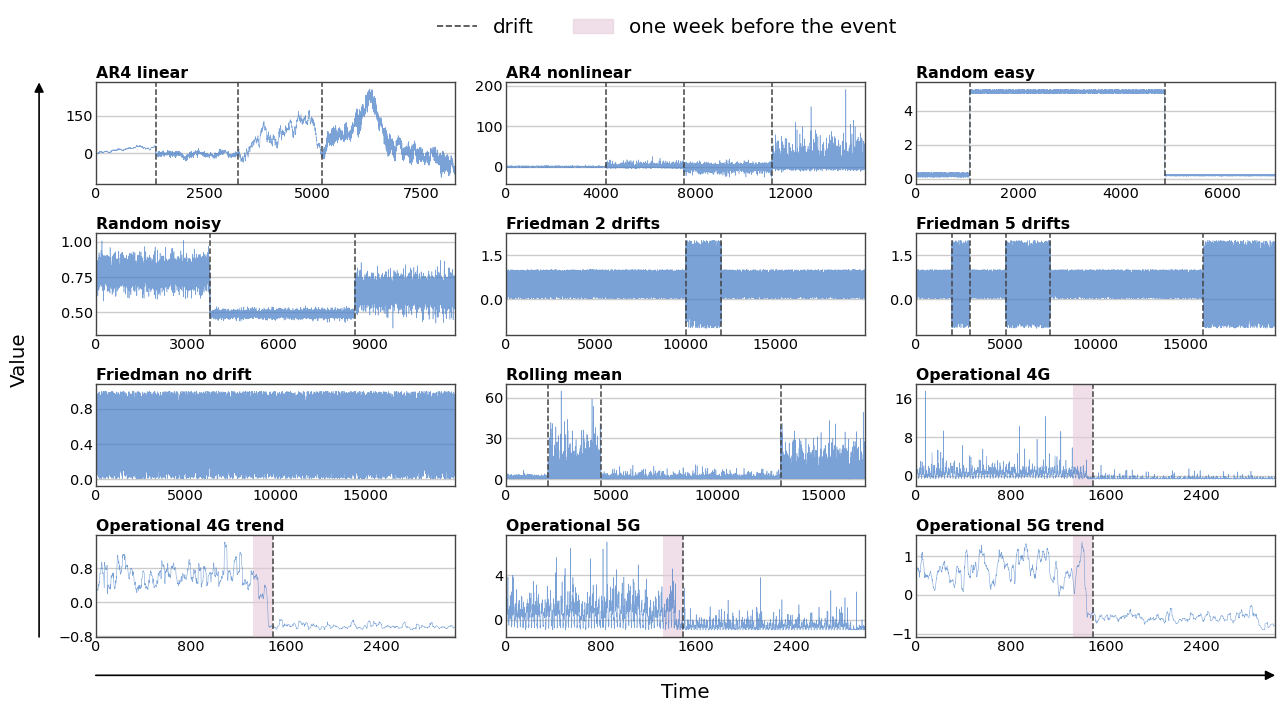

(<Figure size 1260x640 with 12 Axes>,
 array([<Axes: title={'left': 'AR4 linear'}>,
        <Axes: title={'left': 'AR4 nonlinear'}>,
        <Axes: title={'left': 'Random easy'}>,
        <Axes: title={'left': 'Random noisy'}>,
        <Axes: title={'left': 'Friedman 2 drifts'}>,
        <Axes: title={'left': 'Friedman 5 drifts'}>,
        <Axes: title={'left': 'Friedman no drift'}>,
        <Axes: title={'left': 'Rolling mean'}>,
        <Axes: title={'left': 'Operational 4G'}>,
        <Axes: title={'left': 'Operational 4G trend'}>,
        <Axes: title={'left': 'Operational 5G'}>,
        <Axes: title={'left': 'Operational 5G trend'}>], dtype=object))

In [22]:
data_streams = {
    "AR4_linear_1":              data_streams_AR4_linear_1,
    "AR4_nonlinear_1":           data_streams_AR4_nonlinear_1,
    "random_easy":               data_streams_random_easy,
    "random_noisy":              data_streams_random_noisy,
    "friedman_2_drifts":         data_streams_friedman_2_drifts,
    "friedman_5_drifts":         data_streams_friedman_5_drifts,
    "friedman_no_drifts":        data_streams_friedman_no_drifts,
    "rolling_mean":              data_streams_rolling_mean,
    "infocom_4G_add_hour":       data_streams_infocom_4G_add_hour,
    "infocom_4G_add_hour_trend": data_streams_infocom_4G_add_hour_trend,
    "infocom_5G_add_hour":       data_streams_infocom_5G_add_hour,
    "infocom_5G_add_hour_trend": data_streams_infocom_5G_add_hour_trend,
}
stream_labels = {
    "AR4_linear_1":              labels_AR4_linear_1,
    "AR4_nonlinear_1":           labels_AR4_nonlinear_1,
    "random_easy":               labels_random_easy,
    "random_noisy":              labels_random_noisy,
    "friedman_2_drifts":         labels_friedman_2_drifts,
    "friedman_5_drifts":         labels_friedman_5_drifts,
    "friedman_no_drifts":        labels_friedman_no_drifts,
    "rolling_mean":              labels_rolling_mean,
    "infocom_4G_add_hour":       labels_infocom_4G_add_hour,
    "infocom_4G_add_hour_trend": labels_infocom_4G_add_hour_trend,
    "infocom_5G_add_hour":       labels_infocom_5G_add_hour,
    "infocom_5G_add_hour_trend": labels_infocom_5G_add_hour_trend,
}

TS_TITLES = {
    "AR4_linear_1":              "AR4 linear",
    "AR4_nonlinear_1":           "AR4 nonlinear",
    "friedman_2_drifts":         "Friedman 2 drifts",
    "friedman_5_drifts":         "Friedman 5 drifts",
    "friedman_no_drifts":        "Friedman no drift",
    "infocom_4G_add_hour":       "Operational 4G",
    "infocom_4G_add_hour_trend": "Operational 4G trend",
    "infocom_5G_add_hour":       "Operational 5G",
    "infocom_5G_add_hour_trend": "Operational 5G trend",
    "random_easy":               "Random easy",
    "random_noisy":              "Random noisy",
    "rolling_mean":              "Rolling mean",
}

INFOCOM_TS = ["infocom_4G_add_hour", "infocom_4G_add_hour_trend",
              "infocom_5G_add_hour", "infocom_5G_add_hour_trend"]

TS_COLORS = {
    # synthetic (circles)
    "AR4_linear_1":              '#427bc67e',
    "AR4_nonlinear_1":           '#427bc67e',
    "friedman_2_drifts":         '#427bc67e',
    "friedman_5_drifts":         '#427bc67e',
    "friedman_no_drifts":        '#427bc67e',
    "random_easy":               '#427bc67e',  # deeper periwinkle
    "random_noisy":              '#427bc67e',
    "rolling_mean":              '#427bc67e',

    # real / operational (squares)
    "infocom_4G_add_hour":       "#427bc67e",
    "infocom_4G_add_hour_trend": "#427bc67e",
    "infocom_5G_add_hour":       "#427bc67e",  # brighter turquoise
    "infocom_5G_add_hour_trend": "#427bc67e",  # deeper blue
}


plot_stream_examples(
    data_streams, stream_labels,
    order=list(data_streams), stream_idx=0, ts_titles=TS_TITLES,
    colors={**TS_COLORS, "friedman_no_drifts": "#427bc67e"},
    shade_before={ts: 168 for ts in INFOCOM_TS},
    shade_label="one week before the event",
    shade_color="#e6cbd9",                       # stronger pre-event shading
    lw=0.4,                                      # finer line for all streams
    line_alpha=0.7,
    font_scale=1.3,
    save="figures/stream_examples.pdf",
)